# NumCompute Quickstart

A short tour of each NumCompute module, with runnable examples.

In [ ]:
import numpy as np

### Incremental preprocessing

Preprocessing transformers also support `partial_fit()` which allows their parameters to be updated incrementally as new chunks of data arrive.

In [109]:
from numcompute.preprocessing import StandardScaler

stream_scaler = StandardScaler()

chunk1 = np.array([[1.0, 10.0], [2.0, 20.0]])

chunk2 = np.array([[3.0, 30.0], [4.0, 40.0]])

stream_scaler.partial_fit(chunk1)
stream_scaler.partial_fit(chunk2)

print("Running mean: ", stream_scaler.mean_)
print(stream_scaler.transform(chunk2))

Running mean:  [ 2.5 25. ]
[[0.4472136  0.4472136 ]
 [1.34164079 1.34164079]]


## Streaming Statistics

`StreamingStats` updates the statistics incrementally as new chunks of data arrive, allowing the statistics to be calculated incrementally instead of having to process the entire dataset in a single cell.

In [110]:
from numcompute import StreamingStats

stat = StreamingStats()

stat.update_stats(np.array([[1.0, 10.0], [2.0, 20.0]]))
stat.update_stats(np.array([[3.0, 30.0], [4.0, 40.0]]))

print("Mean: ", stat.mean())
print("Variance: ", stat.variance())
print("Minimum: ", stat.min())
print("Maximum: ", stat.max())

Mean:  [ 2.5 25. ]
Variance:  [  1.25 125.  ]
Minimum:  [ 1. 10.]
Maximum:  [ 4. 40.]


## 7. Metrics

The NumCompute package provides useful metrics that can be updated incrementally. By calling the `update` processes a new chunk of predictions while `result` and returns the metric accumulatated across all chunks.

In [111]:
from numcompute.metrics import Accuracy, Precision, Recall, F1, ConfusionMatrix, MSE

pred_array = np.array([1,1,0,0])
true_array = np.array([1,0,0,0])

metrics = [
    Accuracy(),
    Precision(),
    Recall(),
    F1(),
    ConfusionMatrix(),
]
for metric in metrics:
    metric.update(true_array, pred_array)
    print(type(metric).__name__,":", metric.result())

Accuracy : 0.75
Precision : 0.5
Recall : 1.0
F1 : 0.6666666666666666
ConfusionMatrix : (np.int64(1), np.int64(1), np.int64(2), np.int64(0))


### Metrics across chunks

Metric state is preserved between calls to `update`

In [112]:
accuracy = Accuracy()

accuracy.update(np.array([1, 0]), np.array([1, 1]))
accuracy.update(np.array([1, 0]), np.array([1,0]))

print("Cumulative accuracy: ", accuracy.result())

Cumulative accuracy:  0.75


In [113]:
mse = MSE()
mse.update(np.array([1,0.5,1,0]), np.array([2,1,0.5,0]))

print(f"Mean Squared Error: {mse.result()}")

Mean Squared Error: 0.375


In [114]:
from numcompute.metrics import AUC, RollingWindowMetric

auc = AUC()

auc.update(np.array([0, 0]), np.array([0.1, 0.2]))
auc.update(np.array([1, 1]), np.array([0.8, 0.9]))

print(f"AUC: {auc.result()}")

roll_acc = RollingWindowMetric(Accuracy(), window_size=3)

roll_acc.update(np.array([1, 0, 1, 0]), np.array([1, 1, 0, 0]))

print(f"Rolling Accuracy: {roll_acc.result()}")

AUC: 1.0
Rolling Accuracy: 0.3333333333333333


## 5. Pipelines (`pipeline`)

`Pipeline` chains multiple preprocessing steps such that the output of a transformer is automatically passed as the input of the next.

In [115]:
from numcompute.pipeline import Pipeline
from numcompute.tree import DecisionTreeClassifier

X_pipe = np.array([[1.0], [2.0], [3.0], [4.0]])

y_pipe = np.array([0, 0, 1, 1])

stream_pipe = Pipeline([
    ("scale", StandardScaler()), 
    ("model", DecisionTreeClassifier(max_depth=3, buffer_size=4)),
])

stream_pipe.partial_fit(X_pipe[:2], y_pipe[:2])
stream_pipe.partial_fit(X_pipe[2:], y_pipe[2:])

stream_pipe.predict(X_pipe)

array([0., 0., 1., 1.])

## 9. Decision Tree

`DecisionTreeClassifier` implements a depth-limited classification tree that uses either Gini impurity or entropy. 

For streaming data, `partial_fit` stores incoming observations in a buffer, so when `buffer_size` observations have been accumulated, the tree is retrained using the buffered data.

In [116]:
from numcompute.tree import DecisionTreeClassifier

X_tree = np.array([[1.0], [2.0], [3.0], [4.0], [5.0], [6.0]])

y_tree = np.array([0, 0, 0, 1, 1, 1])

tree = DecisionTreeClassifier(max_depth=3, criterion="gini")

tree.fit(X_tree, y_tree)

print(f"Predictions: {tree.predict(X_tree)}")

Predictions: [0. 0. 0. 1. 1. 1.]


In [117]:
stream_tree = DecisionTreeClassifier(max_depth=3, buffer_size=6)

stream_tree.partial_fit(X_tree[:3], y_tree[:3])
stream_tree.partial_fit(X_tree[3:], y_tree[3:])

print(f"Streaming Prediction: {stream_tree.predict(X_tree)}")

Streaming Prediction: [0. 0. 0. 1. 1. 1.]


## 10. Streaming Training

`StreamTrainer` manages incremental model training and evaluation, where it records per-chunk accuracy, cumulative accuracy and an approximate memory footprint.

In [118]:
from numcompute.stream import  StreamTrainer

model = DecisionTreeClassifier(max_depth=3, buffer_size=3)

trainer = StreamTrainer(model)

X_chunk1 = X_tree[:3]
y_chunk1 = y_tree[:3]

X_chunk2 = X_tree[3:]
y_chunk2 = y_tree[3:]

trainer.fit_chunk(X_chunk1, y_chunk1)

print(trainer.score_chunk(X_chunk1, y_chunk1))

trainer.fit_chunk(X_chunk2, y_chunk2)

print(trainer.score_chunk(X_chunk2, y_chunk2))

trainer.get_logs()

{'chunk': 1, 'chunk_acc': np.float64(1.0), 'cum_acc': np.float64(1.0), 'memory_usage': 48}
{'chunk': 2, 'chunk_acc': np.float64(1.0), 'cum_acc': np.float64(1.0), 'memory_usage': 48}


[{'chunk': 1,
  'chunk_acc': np.float64(1.0),
  'cum_acc': np.float64(1.0),
  'memory_usage': 48},
 {'chunk': 2,
  'chunk_acc': np.float64(1.0),
  'cum_acc': np.float64(1.0),
  'memory_usage': 48}]

## 11. Visualisation

The NumCompute package also provide reusable Matplotlib function that show streaming metrics, comparing models, and 
comparing predictions with ground truth.

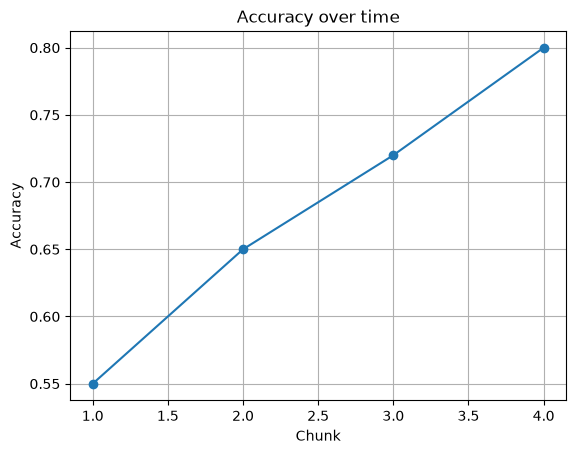

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Accuracy over time'}, xlabel='Chunk', ylabel='Accuracy'>)

In [119]:
from numcompute.visualise import (
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth
)

metric_values = [0.55, 0.65, 0.72, 0.80]

plot_metric_over_time(metric_values, "Accuracy over time", "Accuracy")

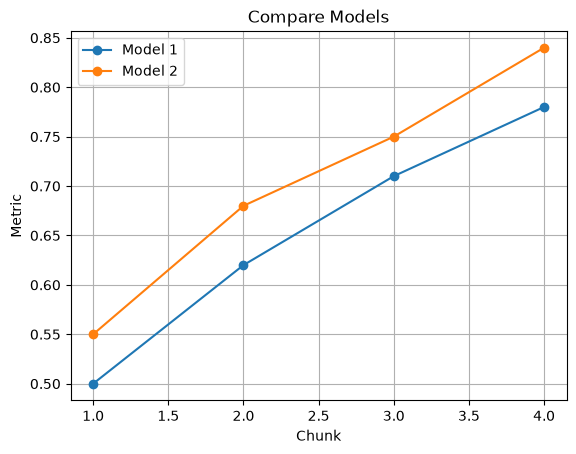

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Compare Models'}, xlabel='Chunk', ylabel='Metric'>)

In [120]:
compare_models([0.50, 0.62, 0.71, 0.78], [0.55, 0.68, 0.75, 0.84], ["Model 1", "Model 2"])

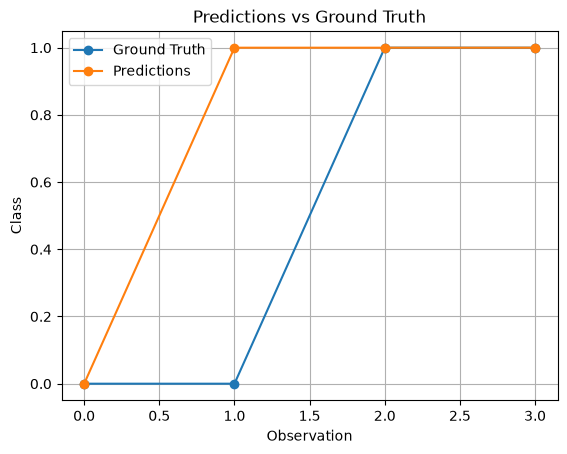

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Predictions vs Ground Truth'}, xlabel='Observation', ylabel='Class'>)

In [121]:
plot_predictions_vs_ground_truth(np.array([0, 0, 1, 1]), np.array([0, 1, 1, 1]))

## 12. Benchmarking

For very small inputs, execution times can be noisy and overhead can dominate
the result, so these timings should not be interpreted as representative of
large-scale performance.

### Streaming benchmark

The streaming benchmark compares the loop-based and vectorised incremental statistics used by `StandardScaler`.

In [122]:
from numcompute.benchmarking import(
    benchmark_streaming_scaler,
    benchmark_buffer_sizes
)

rng = np.random.default_rng(42)

X_benchmark = rng.normal(size=(10_000, 10))

scaler_results = benchmark_streaming_scaler(X_benchmark, size_of_chunk=500, repeat=5)

scaler_results

Streaming StandardScaler Benchmark
The Python loop average was: 16.728051 ms
The vectorised average was: 0.782513 ms
Vectorised speed-up was: 21.377346x


{'loop_times_ms': array([16.568301, 16.807763, 16.842366, 16.703963, 16.717861]),
 'vectorised_times_ms': array([0.787882, 0.869988, 0.733778, 0.734962, 0.785955]),
 'loop_average_ms': np.float64(16.72805080015678),
 'vectorised_average_ms': np.float64(0.7825130000128411),
 'speed_up': np.float64(21.377345551936227)}

### Decision Tree buffer-size benchmark

Different buffer size are evaluated to see how frequently the streaming decision tree is retrained, the benchmark records the execution time and the final accuracy.

In [123]:
X_tree_benchmark = rng.normal(size=(1000, 4))

y_tree_benchmark = (X_tree_benchmark[:, 0] + X_tree_benchmark[:, 1] > 0).astype(int)

buffer_results = benchmark_buffer_sizes(
    X_tree_benchmark,
    y_tree_benchmark, 
    buffer_sizes=[50, 100, 250],
    size_of_chunk=50,
    repeat=3,
    max_depth=5
)

buffer_results

Decision Tree Buffer Benchmark
Buffer size: 50
Average training time: 117.531593 ms
Final Accuracy: 0.8470
Buffer size: 100
Average training time: 133.322133 ms
Final Accuracy: 0.9250
Buffer size: 250
Average training time: 170.139033 ms
Final Accuracy: 0.9530


[{'buffer_size': 50,
  'times_ms': array([112.135443, 127.580826, 112.878509]),
  'avg_time_ms': np.float64(117.53159266421183),
  'accuracy': np.float64(0.847)},
 {'buffer_size': 100,
  'times_ms': array([132.115673, 133.640638, 134.210089]),
  'avg_time_ms': np.float64(133.32213333584755),
  'accuracy': np.float64(0.925)},
 {'buffer_size': 250,
  'times_ms': array([169.372535, 171.527158, 169.517405]),
  'avg_time_ms': np.float64(170.13903266585353),
  'accuracy': np.float64(0.953)}]

Benchmark environment: Python 3.14.4. Results are machine-specific and may vary depending on hardware and system load.